# JAX for RL: LunarLander three ways, and where the speed actually comes from

JAX is sold to RL people as "100x faster". That is true for one specific setup and
false for the one most people have. This notebook measures both.

**What you'll see:**

1. PPO written from scratch in **Flax + Optax** (about 120 lines, one cell), solving
   LunarLander-v3
2. The same problem with **SBX** (Stable-Baselines-JAX) and with plain **SB3**
   (PyTorch), on the same budget, with the wall clock next to the score
3. A **fully jitted** PPO where the environment is JAX too (gymnax CartPole), training
   eight seeds at once — the setup the "100x" numbers come from
4. Three JAX failure modes that produce **no error**: a reused random key, a timing
   that measures nothing, and a function that silently recompiles

Nothing here needs a GPU. Everything ran on a laptop CPU (Apple M-series); the run
times are printed next to each result. The whole notebook takes about 35 minutes.

*Everything is self-contained — no imports from this repo.*

## 0. The problem

**LunarLander-v3** (Gymnasium, Box2D physics). A lander starts at the top of the
screen with a random push. Fire the engines to land it between the two flags.

| | |
|---|---|
| Observation | 8 numbers, below |
| Actions | 4 discrete: do nothing, fire left engine, fire main engine, fire right engine |
| Reward | moving towards the pad and slowing down earns reward; each leg on the ground +10; crash −100; landing at rest +100; main engine −0.3 per frame, side engines −0.03 |
| Episode end | crash, landing at rest, flying off screen, or 1,000 steps |
| "Solved" | an average return of **200** over 100 episodes |

| Column | Meaning |
|---|---|
| `x` | horizontal position, 0 = the pad centre |
| `y` | height above the pad |
| `vx`, `vy` | horizontal and vertical velocity |
| `angle` | tilt in radians, 0 = upright |
| `ang_vel` | angular velocity |
| `left_leg`, `right_leg` | 1 if that leg touches the ground, else 0 |

In [1]:
import time, numpy as np, pandas as pd, matplotlib.pyplot as plt
import gymnasium as gym

COLS = ["x", "y", "vx", "vy", "angle", "ang_vel", "left_leg", "right_leg"]
env = gym.make("LunarLander-v3")
obs, _ = env.reset(seed=0)
rows, rng = [], np.random.default_rng(0)
for t in range(400):
    a = int(rng.integers(4))
    nxt, r, term, trunc, _ = env.step(a)
    rows.append(dict(zip(COLS, obs.round(3)), action=a, reward=round(float(r), 2)))
    obs = nxt
    if term or trunc:
        break
df = pd.DataFrame(rows)
print(f"one random episode: {len(df)} steps, return {df.reward.sum():.1f}")
df.iloc[list(range(4)) + list(range(len(df) - 4, len(df)))]

one random episode: 66 steps, return -190.0


,x,y,vx,vy,angle,ang_vel,left_leg,right_leg,action,reward
0,0.006,1.399,0.578,-0.528,-0.007,-0.131,0.0,0.0,3,-2.04
1,0.011,1.387,0.587,-0.554,-0.015,-0.170,0.0,0.0,2,0.91
2,0.017,1.374,0.585,-0.543,-0.024,-0.172,0.0,0.0,2,0.75
3,0.023,1.362,0.573,-0.545,-0.033,-0.186,0.0,0.0,1,-0.69
62,0.440,0.121,1.054,-1.362,-0.828,-0.349,1.0,0.0,2,26.86
63,0.447,0.105,0.877,-0.842,-1.059,-4.305,1.0,0.0,1,-23.61
64,0.455,0.090,0.866,-0.865,-1.283,-4.238,1.0,0.0,3,-14.60
65,0.462,0.077,0.797,-0.764,-1.543,-5.134,1.0,0.0,0,-100.00


The last rows are the crash: the legs touch, the reward jumps by −100.
A random policy almost always crashes. Here is its return over 100 episodes — this
is the floor every learner has to climb from.

random policy: mean -196.5, median -164.8, best 0.8


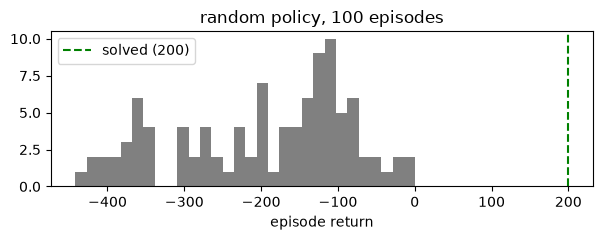

In [2]:
def run_episode(policy, seed):
    env = gym.make("LunarLander-v3")
    obs, _ = env.reset(seed=seed); total, done = 0.0, False
    while not done:
        obs, r, term, trunc, _ = env.step(policy(obs)); total += r; done = term or trunc
    return total

rng = np.random.default_rng(1)
random_returns = np.array([run_episode(lambda o: int(rng.integers(4)), seed=1000 + i) for i in range(100)])
print(f"random policy: mean {random_returns.mean():.1f}, median {np.median(random_returns):.1f}, best {random_returns.max():.1f}")
plt.figure(figsize=(6, 2.5)); plt.hist(random_returns, bins=30, color="grey")
plt.axvline(200, color="green", ls="--", label="solved (200)"); plt.xlabel("episode return"); plt.legend(); plt.title("random policy, 100 episodes")
plt.tight_layout(); plt.show()

## 1. JAX in one screen

Three functions do all the work in this notebook.

- `jax.jit(f)` traces `f` once with abstract shapes, compiles it with XLA, and runs
  the compiled version every later call.
- `jax.vmap(f)` turns a function of one example into a function of a batch — without
  you writing the batch dimension.
- `jax.grad(f)` returns the gradient function of a scalar `f`.

And one rule that changes how you write code: **randomness is explicit.** There is
no global random state; every random call takes a `key`, and you `split` keys to get
new ones. Section 6a shows what happens when you forget.

In [3]:
import jax, jax.numpy as jnp
print("jax", jax.__version__, "devices", jax.devices())

def mlp(params, x):                      # one example in, one number out
    for W, b in params[:-1]:
        x = jnp.tanh(x @ W + b)
    W, b = params[-1]
    return (x @ W + b)[0]

key = jax.random.PRNGKey(0)
sizes = [8, 64, 64, 1]
params = []
for m, n in zip(sizes[:-1], sizes[1:]):
    key, k = jax.random.split(key)
    params.append((jax.random.normal(k, (m, n)) / np.sqrt(m), jnp.zeros(n)))

x = jnp.ones(8)
batched = jax.vmap(mlp, in_axes=(None, 0))               # params shared, x batched
grad_fn = jax.grad(lambda p, x: batched(p, x).mean())    # gradient w.r.t. params
X = jax.random.normal(key, (4096, 8))
print("one example:", float(mlp(params, x)), "| batch:", batched(params, X).shape,
      "| grad of layer-1 W:", grad_fn(params, X)[0][0].shape)

slow, fast = batched, jax.jit(batched)
fast(params, X).block_until_ready()                      # compile once
for name, f in [("no jit", slow), ("jit", fast)]:
    t = time.perf_counter()
    for _ in range(200):
        f(params, X).block_until_ready()
    print(f"{name:7s} {1e6 * (time.perf_counter() - t) / 200:8.1f} us per call")

jax 0.11.1 devices [CpuDevice(id=0)]


one example: 0.4135386347770691 | batch: (4096,) | grad of layer-1 W: (8, 64)
no jit     792.4 us per call


jit        358.3 us per call


## 2. Where the time goes

PPO alternates two phases. Only one of them can be JAX when the simulator is Box2D.

```
        ┌──────────── rollout: 16 envs x 256 steps ────────────┐
        │                                                       │
   Box2D physics (CPU, Python, one env at a time)  ◄──actions── policy forward (JAX, jitted)
        │                                                       ▲
        └──observations, rewards─────────────────────────────────┘
                              │
                              ▼
        update: GAE + 4 epochs x 8 minibatches of the clipped loss (JAX, jitted, one call)
```

The update is one compiled XLA call, so it is cheap. The rollout crosses the
Python/JAX boundary **every step**: numpy observations go in, a JAX array of actions
comes out, and Box2D steps sixteen environments in a Python loop. Section 3 times
both phases separately.

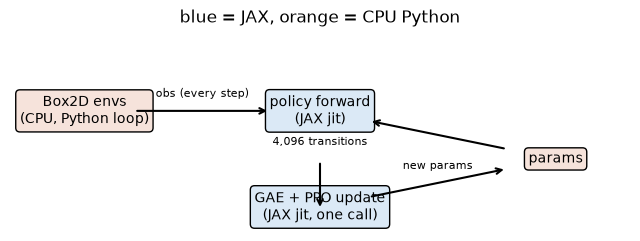

In [4]:
fig, ax = plt.subplots(figsize=(8, 2.6)); ax.axis("off")
boxes = {"Box2D envs\n(CPU, Python loop)": (0.12, 0.6), "policy forward\n(JAX jit)": (0.5, 0.6),
         "GAE + PPO update\n(JAX jit, one call)": (0.5, 0.12), "params": (0.88, 0.36)}
for text, (x, y) in boxes.items():
    ax.text(x, y, text, ha="center", va="center", fontsize=10,
            bbox=dict(boxstyle="round", fc="#dbe9f6" if "JAX" in text else "#f6e3db"))
def arrow(a, b, label):
    ax.annotate("", xy=boxes[b], xytext=boxes[a], arrowprops=dict(arrowstyle="->", lw=1.5, shrinkA=38, shrinkB=38))
    ax.text((boxes[a][0] + boxes[b][0]) / 2, (boxes[a][1] + boxes[b][1]) / 2 + 0.07, label, ha="center", fontsize=8)
arrow("Box2D envs\n(CPU, Python loop)", "policy forward\n(JAX jit)", "obs (every step)")
arrow("policy forward\n(JAX jit)", "GAE + PPO update\n(JAX jit, one call)", "4,096 transitions")
arrow("GAE + PPO update\n(JAX jit, one call)", "params", "new params")
arrow("params", "policy forward\n(JAX jit)", "")
ax.set_title("blue = JAX, orange = CPU Python"); plt.show()

## 3. PPO from scratch in Flax + Optax

One cell. The parts, in order: the network (separate actor and critic MLPs), the
jitted action sampler, GAE as a reverse `lax.scan`, the clipped loss, and the update
as one jitted function that loops epochs and minibatches with `lax.scan`.

Two details that are easy to get wrong:

- **Time limits are not terminations.** An episode cut at 1,000 steps did not end;
  its value is bootstrapped from the final observation. Treating it as a crash
  teaches the lander that hovering is fatal.
- The health panel logs **approx KL**, **clip fraction**, **entropy** and
  **explained variance** every update. A run that does not learn usually shows it
  there first (entropy collapsing to 0, KL near 0, explained variance negative).

Hyperparameters are the RL-Zoo PPO settings for LunarLander, apart from the batch
layout: 16 environments, γ = 0.999, λ = 0.98, entropy 0.01.

In [5]:
import optax, flax.linen as nn
from functools import partial
from flax.training.train_state import TrainState

class ActorCritic(nn.Module):
    n_actions: int
    @nn.compact
    def __call__(self, x):
        ortho = nn.initializers.orthogonal
        a = nn.tanh(nn.Dense(64, kernel_init=ortho(np.sqrt(2)))(x))
        a = nn.tanh(nn.Dense(64, kernel_init=ortho(np.sqrt(2)))(a))
        logits = nn.Dense(self.n_actions, kernel_init=ortho(0.01))(a)
        v = nn.tanh(nn.Dense(64, kernel_init=ortho(np.sqrt(2)))(x))
        v = nn.tanh(nn.Dense(64, kernel_init=ortho(np.sqrt(2)))(v))
        return logits, nn.Dense(1, kernel_init=ortho(1.0))(v)[..., 0]

CFG = dict(n_envs=16, n_steps=256, epochs=4, n_minibatch=8, gamma=0.999, lam=0.98, clip=0.2,
           ent=0.01, vf=0.5, lr=3e-4, lr_end=0.0, max_grad=0.5, total_steps=2_000_000, seed=0)
net = ActorCritic(4)

@jax.jit
def act(params, obs, key):
    logits, v = net.apply(params, obs)
    a = jax.random.categorical(key, logits)
    return a, jax.nn.log_softmax(logits)[jnp.arange(a.shape[0]), a], v

@jax.jit
def gae(rew, val, done, last_val):
    # rew, val, done: (T, N). done=1 cuts the bootstrap; truncation was folded into rew before.
    def step(carry, x):
        adv_next, v_next = carry
        r, v, d = x
        delta = r + CFG["gamma"] * v_next * (1 - d) - v
        adv = delta + CFG["gamma"] * CFG["lam"] * (1 - d) * adv_next
        return (adv, v), adv
    _, adv = jax.lax.scan(step, (jnp.zeros_like(last_val), last_val), (rew, val, done), reverse=True)
    return adv, adv + val

def loss_fn(params, b):
    logits, v = net.apply(params, b["obs"])
    logp_all = jax.nn.log_softmax(logits)
    logp = jnp.take_along_axis(logp_all, b["act"][:, None], 1)[:, 0]
    ratio = jnp.exp(logp - b["logp"])
    adv = (b["adv"] - b["adv"].mean()) / (b["adv"].std() + 1e-8)
    pg = -jnp.minimum(ratio * adv, jnp.clip(ratio, 1 - CFG["clip"], 1 + CFG["clip"]) * adv).mean()
    vl = 0.5 * ((v - b["ret"]) ** 2).mean()
    ent = -(jnp.exp(logp_all) * logp_all).sum(-1).mean()
    return pg + CFG["vf"] * vl - CFG["ent"] * ent, dict(
        entropy=ent, approx_kl=((ratio - 1) - jnp.log(ratio)).mean(), clipfrac=(jnp.abs(ratio - 1) > CFG["clip"]).mean())

@partial(jax.jit, static_argnums=3)
def update(state, batch, key, n_minibatch):
    n = batch["obs"].shape[0]
    def epoch(carry, k):
        state = carry
        perm = jax.random.permutation(k, n)
        mbs = jax.tree.map(lambda x: x[perm].reshape(n_minibatch, -1, *x.shape[1:]), batch)
        def mb_step(state, mb):
            (_, info), g = jax.value_and_grad(loss_fn, has_aux=True)(state.params, mb)
            return state.apply_gradients(grads=g), info
        state, info = jax.lax.scan(mb_step, state, mbs)
        return state, info
    state, info = jax.lax.scan(epoch, state, jax.random.split(key, CFG["epochs"]))
    return state, jax.tree.map(jnp.mean, info)

def train_ppo(cfg):
    n_env, T = cfg["n_envs"], cfg["n_steps"]
    n_updates = cfg["total_steps"] // (n_env * T)
    envs = gym.make_vec("LunarLander-v3", num_envs=n_env, vectorization_mode="sync",
                        vector_kwargs={"autoreset_mode": gym.vector.AutoresetMode.SAME_STEP})
    obs, _ = envs.reset(seed=cfg["seed"])
    key = jax.random.PRNGKey(cfg["seed"])
    key, k = jax.random.split(key)
    sched = optax.linear_schedule(cfg["lr"], cfg["lr_end"], n_updates * cfg["epochs"] * cfg["n_minibatch"])
    state = TrainState.create(apply_fn=net.apply, params=net.init(k, jnp.zeros((1, 8))),
                              tx=optax.chain(optax.clip_by_global_norm(cfg["max_grad"]), optax.adam(sched, eps=1e-5)))
    ep_ret, log, finished = np.zeros(n_env), [], []
    t_env = t_act = t_upd = 0.0
    for u in range(n_updates):
        buf = {k: np.zeros((T, n_env) + s, dtype=d) for k, s, d in
               [("obs", (8,), np.float32), ("act", (), np.int32), ("logp", (), np.float32),
                ("val", (), np.float32), ("rew", (), np.float32), ("done", (), np.float32)]}
        for t in range(T):
            key, k = jax.random.split(key)
            t0 = time.perf_counter()
            a, logp, v = act(state.params, obs, k)
            a = np.asarray(a); t1 = time.perf_counter()
            nxt, r, term, trunc, info = envs.step(a); t2 = time.perf_counter()
            t_act += t1 - t0; t_env += t2 - t1
            r = r.astype(np.float32)
            ep_ret += r
            cut = trunc & ~term                                    # time limit: bootstrap, do not treat as a crash
            if cut.any():
                final = np.stack(info["final_obs"][cut]).astype(np.float32)
                r[cut] += cfg["gamma"] * np.asarray(net.apply(state.params, final)[1])
            for i in np.flatnonzero(term | trunc):
                finished.append(ep_ret[i]); ep_ret[i] = 0.0
            for name, x in [("obs", obs), ("act", a), ("logp", logp), ("val", v), ("rew", r), ("done", term | trunc)]:
                buf[name][t] = np.asarray(x)
            obs = nxt
        t0 = time.perf_counter()
        last_v = net.apply(state.params, obs)[1]
        adv, ret = gae(jnp.asarray(buf["rew"]), jnp.asarray(buf["val"]), jnp.asarray(buf["done"]), last_v)
        batch = dict(obs=buf["obs"].reshape(-1, 8), act=buf["act"].reshape(-1), logp=buf["logp"].reshape(-1),
                     adv=adv.reshape(-1), ret=ret.reshape(-1))
        key, k = jax.random.split(key)
        state, info = update(state, batch, k, cfg["n_minibatch"])
        ev = 1 - np.var(np.asarray(ret) - buf["val"]) / (np.var(np.asarray(ret)) + 1e-8)
        jax.block_until_ready(state.params); t_upd += time.perf_counter() - t0
        recent = np.mean(finished[-50:]) if finished else np.nan
        log.append(dict(step=(u + 1) * n_env * T, ret50=recent, explained_var=ev, **{k: float(v) for k, v in info.items()}))
        if u % 40 == 0 or u == n_updates - 1:
            print(f"step {log[-1]['step']:>9,}  return(last 50) {recent:7.1f}  entropy {log[-1]['entropy']:.3f}  "
                  f"kl {log[-1]['approx_kl']:.4f}  clip {log[-1]['clipfrac']:.3f}  EV {ev:.2f}")
    times = dict(env=t_env, policy=t_act, update=t_upd)
    return state, pd.DataFrame(log), times

print("run A: 8 minibatches of 512, learning rate decaying to 0")
t = time.perf_counter()
state_a, log_a, times_a = train_ppo(CFG)
wall_a = time.perf_counter() - t
print(f"\nwall clock {wall_a:.0f} s for {CFG['total_steps']:,} steps; split: " +
      ", ".join(f"{k} {v:.0f} s ({100 * v / sum(times_a.values()):.0f}%)" for k, v in times_a.items()))

run A: 8 minibatches of 512, learning rate decaying to 0


step     4,096  return(last 50)  -184.7  entropy 1.386  kl 0.0001  clip 0.000  EV 0.00


step   167,936  return(last 50)   -29.7  entropy 1.142  kl 0.0012  clip 0.004  EV 0.00


step   331,776  return(last 50)    54.5  entropy 1.059  kl 0.0002  clip 0.000  EV 0.63


step   495,616  return(last 50)    70.3  entropy 0.999  kl 0.0018  clip 0.020  EV 0.90


step   659,456  return(last 50)    96.4  entropy 0.996  kl 0.0015  clip 0.003  EV 0.81


... (5 outputs left out)

step 1,642,496  return(last 50)   102.5  entropy 0.977  kl 0.0001  clip 0.000  EV 0.72


step 1,806,336  return(last 50)   101.7  entropy 1.040  kl 0.0001  clip 0.000  EV 0.80


step 1,970,176  return(last 50)    79.6  entropy 1.009  kl 0.0000  clip 0.000  EV 0.75


step 1,998,848  return(last 50)    88.8  entropy 0.920  kl 0.0000  clip 0.000  EV 0.65

wall clock 101 s for 2,000,000 steps; split: env 59 s (75%), policy 9 s (11%), update 11 s (14%)


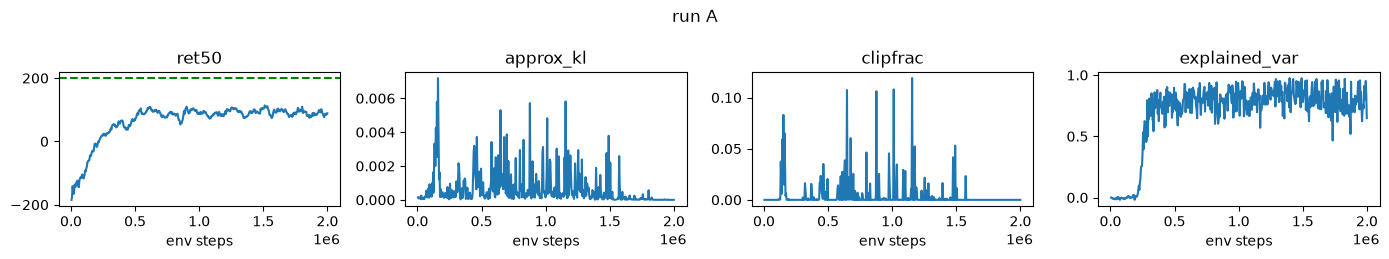

run A, greedy, 100 fresh episodes: mean 23.8, 0% at 200 or more


In [6]:
def panel(log, title):
    fig, axs = plt.subplots(1, 4, figsize=(14, 2.6))
    for ax, col in zip(axs, ["ret50", "approx_kl", "clipfrac", "explained_var"]):
        ax.plot(log.step, log[col]); ax.set_title(col); ax.set_xlabel("env steps")
    axs[0].axhline(200, color="green", ls="--"); fig.suptitle(title); plt.tight_layout(); plt.show()

def greedy_eval(params):
    pol = lambda o: int(jnp.argmax(net.apply(params, jnp.asarray(o[None], jnp.float32))[0][0]))
    return np.array([run_episode(pol, seed=5000 + i) for i in range(100)])

panel(log_a, "run A")
ours_a = greedy_eval(state_a.params)
print(f"run A, greedy, 100 fresh episodes: mean {ours_a.mean():.1f}, {(ours_a >= 200).mean():.0%} at 200 or more")

### What the health panel says about run A

Read the KL and clip-fraction panels before the return. PPO's clip only matters if
the policy moves far enough to reach it. If the clip fraction sits near 0 and the
approximate KL near 1e-4, the clip never binds: each update barely changes the
policy, and the learning rate is decaying the step size towards zero on top of that.

Count the gradient steps. Run A takes 4 epochs x 8 minibatches = 32 gradient steps
per 4,096 samples, one step per 128 samples. The RL-Zoo settings that SB3 uses
(section 4) take 4 epochs x 256 minibatches of 64 per 16,384 samples, one step per
16 samples: eight times more. Run B keeps everything else and changes exactly those
two things: 64 minibatches of 64, and a constant learning rate.

run B: 64 minibatches of 64, constant learning rate


step     4,096  return(last 50)  -184.7  entropy 1.384  kl 0.0018  clip 0.007  EV 0.00


step   167,936  return(last 50)    43.4  entropy 1.023  kl 0.0020  clip 0.019  EV 0.84


step   331,776  return(last 50)    54.7  entropy 0.911  kl 0.0057  clip 0.069  EV 0.85


step   495,616  return(last 50)   128.1  entropy 0.894  kl 0.0037  clip 0.037  EV 0.89


step   659,456  return(last 50)   209.8  entropy 0.788  kl 0.0031  clip 0.032  EV 0.53


... (5 outputs left out)

step 1,642,496  return(last 50)   257.3  entropy 0.638  kl 0.0037  clip 0.038  EV 0.99


step 1,806,336  return(last 50)   252.0  entropy 0.636  kl 0.0024  clip 0.024  EV 0.96


step 1,970,176  return(last 50)   269.1  entropy 0.591  kl 0.0046  clip 0.056  EV 0.98


step 1,998,848  return(last 50)   264.3  entropy 0.679  kl 0.0069  clip 0.087  EV 0.99

wall clock 92 s for 2,000,000 steps; split: env 54 s (70%), policy 8 s (10%), update 15 s (20%)


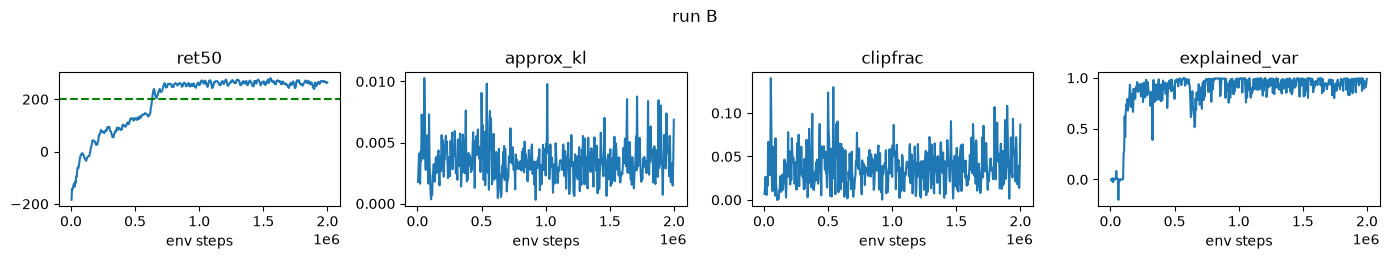

run B, greedy, 100 fresh episodes: mean 271.9, 99% at 200 or more


In [7]:
CFG_B = dict(CFG, n_minibatch=64, lr_end=CFG["lr"])
print("run B: 64 minibatches of 64, constant learning rate")
t = time.perf_counter()
state, ppo_log, ppo_times = train_ppo(CFG_B)
ppo_wall = time.perf_counter() - t
print(f"\nwall clock {ppo_wall:.0f} s for {CFG_B['total_steps']:,} steps; split: " +
      ", ".join(f"{k} {v:.0f} s ({100 * v / sum(ppo_times.values()):.0f}%)" for k, v in ppo_times.items()))
panel(ppo_log, "run B")
ours = greedy_eval(state.params)
print(f"run B, greedy, 100 fresh episodes: mean {ours.mean():.1f}, {(ours >= 200).mean():.0%} at 200 or more")

**Reading the split.** The `env` share is the Box2D step plus the Python loop around
it; `policy` is the jitted forward pass including the device round trip;
`update` is GAE plus every minibatch step of each update. If `env` dominates,
a faster network or a GPU buys nothing — the simulator is the ceiling.

## 4. SBX: Stable-Baselines, JAX inside

[SBX](https://github.com/araffin/sbx) keeps the SB3 interface and replaces the
PyTorch internals with JAX. So the honest comparison is SBX against SB3 with the
**same** algorithm, hyperparameters and step budget: the only difference is the
framework.

Budget: 1,000,000 steps for PPO (RL-Zoo LunarLander settings: 16 envs, `n_steps`
1024, batch 64, 4 epochs). DQN uses the RL-Zoo hyperparameters with 300,000 steps,
three times the Zoo budget. One seed each — read the scores as one sample, not as a
ranking.

The wall clocks were measured on a laptop that was also running a 6-worker training
job, so treat the steps-per-second column as rough. The environment is the same Python
Box2D loop for all three.

In [8]:
import os, tempfile
from stable_baselines3 import PPO as SB3_PPO
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.monitor import load_results
from sbx import PPO as SBX_PPO, DQN as SBX_DQN

ZOO_PPO = dict(n_steps=1024, batch_size=64, n_epochs=4, gamma=0.999, gae_lambda=0.98, ent_coef=0.01, verbose=0, seed=0)
ZOO_DQN = dict(learning_rate=6.3e-4, batch_size=128, buffer_size=50_000, learning_starts=0, gamma=0.99,
               target_update_interval=250, train_freq=4, gradient_steps=-1, exploration_fraction=0.12,
               exploration_final_eps=0.1, policy_kwargs=dict(net_arch=[256, 256]), verbose=0, seed=0)
runs = {}
for name, algo, kw, n_env, steps in [("SBX PPO", SBX_PPO, ZOO_PPO, 16, 1_000_000),
                                     ("SB3 PPO (torch)", SB3_PPO, ZOO_PPO, 16, 1_000_000),
                                     ("SBX DQN", SBX_DQN, ZOO_DQN, 1, 300_000)]:
    mon = tempfile.mkdtemp()
    venv = make_vec_env("LunarLander-v3", n_envs=n_env, seed=0, monitor_dir=mon)
    model = algo("MlpPolicy", venv, **kw)
    t = time.perf_counter(); model.learn(steps); wall = time.perf_counter() - t
    pol = lambda o, m=model: int(m.predict(o, deterministic=True)[0])
    rets = np.array([run_episode(pol, seed=5000 + i) for i in range(100)])
    curve = load_results(mon).sort_values("t")
    runs[name] = dict(wall=wall, steps=steps, rets=rets, curve=curve)
    print(f"{name:16s} {steps:>9,} steps  {wall:6.0f} s  ({steps / wall:7.0f} steps/s)  "
          f"greedy mean {rets.mean():6.1f}, {(rets >= 200).mean():.0%} at 200+")

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


SBX PPO          1,000,000 steps     599 s  (   1670 steps/s)  greedy mean  255.9, 100% at 200+


SB3 PPO (torch)  1,000,000 steps     610 s  (   1639 steps/s)  greedy mean  255.7, 99% at 200+


SBX DQN            300,000 steps     331 s  (    907 steps/s)  greedy mean  255.8, 90% at 200+


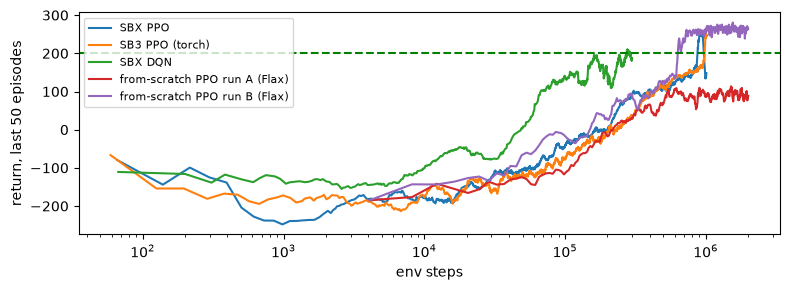

,run,steps,wall_s,greedy_mean,solved_share,steps_per_s
0,"from-scratch PPO, run A (Flax)",2000000,101.20,23.83,0.00,19762.94
1,"from-scratch PPO, run B (Flax)",2000000,91.96,271.85,0.99,21749.37
2,SBX PPO,1000000,598.78,255.93,1.00,1670.05
3,SB3 PPO (torch),1000000,610.20,255.73,0.99,1638.80
4,SBX DQN,300000,330.75,255.76,0.90,907.02


In [9]:
fig, ax = plt.subplots(figsize=(8, 3))
for name, r in runs.items():
    c = r["curve"]; ax.plot(np.cumsum(c.l.values), c.r.rolling(50, min_periods=1).mean(), label=name)
ax.plot(log_a.step, log_a.ret50, label="from-scratch PPO run A (Flax)")
ax.plot(ppo_log.step, ppo_log.ret50, label="from-scratch PPO run B (Flax)")
ax.axhline(200, color="green", ls="--"); ax.set_xlabel("env steps"); ax.set_ylabel("return, last 50 episodes")
ax.set_xscale("log"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

summary = pd.DataFrame([dict(run="from-scratch PPO, run A (Flax)", steps=CFG["total_steps"], wall_s=wall_a,
                             greedy_mean=ours_a.mean(), solved_share=(ours_a >= 200).mean()),
                        dict(run="from-scratch PPO, run B (Flax)", steps=CFG_B["total_steps"], wall_s=ppo_wall,
                             greedy_mean=ours.mean(), solved_share=(ours >= 200).mean())] +
                       [dict(run=k, steps=v["steps"], wall_s=v["wall"], greedy_mean=v["rets"].mean(),
                             solved_share=(v["rets"] >= 200).mean()) for k, v in runs.items()])
summary["steps_per_s"] = summary.steps / summary.wall_s
summary.round(2)

## 5. When the environment is JAX too

Everything above keeps a CPU simulator in the loop, so JAX can only speed up the
network. [gymnax](https://github.com/RobertTLange/gymnax) re-implements classic
environments in JAX. Then the **whole training run** — environment steps, rollouts,
GAE, updates — compiles into one XLA program, and `vmap` over the random seed trains
several independent agents in one call.

There is no gymnax LunarLander: Box2D is a C++ physics engine and cannot be traced.
So this section uses **CartPole-v1** (max return 500). The point is the shape of
the speed-up, not the environment.

This is the PureJaxRL pattern (Lu et al., 2022), cut down to the essentials.

In [10]:
if not hasattr(jax, "tree_map"):
    jax.tree_map = jax.tree.map          # gymnax 0.0.8 still calls jax.tree_map, which jax 0.11 removed
import gymnax
genv, gparams = gymnax.make("CartPole-v1")
G = dict(n_envs=8, n_steps=128, epochs=4, n_minibatch=4, gamma=0.99, lam=0.95, clip=0.2, ent=0.01, vf=0.5,
         lr=2.5e-4, total_steps=500_000)
G_UPDATES = G["total_steps"] // (G["n_envs"] * G["n_steps"])
gnet = ActorCritic(genv.num_actions)

def make_train(seed_key):
    def g_loss(params, b):
        logits, v = gnet.apply(params, b["obs"])
        lp_all = jax.nn.log_softmax(logits)
        lp = jnp.take_along_axis(lp_all, b["act"][:, None], 1)[:, 0]
        ratio = jnp.exp(lp - b["logp"])
        adv = (b["adv"] - b["adv"].mean()) / (b["adv"].std() + 1e-8)
        pg = -jnp.minimum(ratio * adv, jnp.clip(ratio, 1 - G["clip"], 1 + G["clip"]) * adv).mean()
        ent = -(jnp.exp(lp_all) * lp_all).sum(-1).mean()
        return pg + G["vf"] * 0.5 * ((v - b["ret"]) ** 2).mean() - G["ent"] * ent

    k_init, k_env, k_run = jax.random.split(seed_key, 3)
    tx = optax.chain(optax.clip_by_global_norm(0.5),
                     optax.adam(optax.linear_schedule(G["lr"], 0.0, G_UPDATES * G["epochs"] * G["n_minibatch"]), eps=1e-5))
    state = TrainState.create(apply_fn=gnet.apply, params=gnet.init(k_init, jnp.zeros((1, 4))), tx=tx)
    obs, env_state = jax.vmap(genv.reset, in_axes=(0, None))(jax.random.split(k_env, G["n_envs"]), gparams)

    def env_step(carry, _):
        state, obs, env_state, ep_ret, key = carry
        key, k_a, k_s = jax.random.split(key, 3)
        logits, v = gnet.apply(state.params, obs)
        a = jax.random.categorical(k_a, logits)
        lp = jax.nn.log_softmax(logits)[jnp.arange(G["n_envs"]), a]
        obs2, env_state, r, done, _ = jax.vmap(genv.step, in_axes=(0, 0, 0, None))(
            jax.random.split(k_s, G["n_envs"]), env_state, a, gparams)
        ep_ret = ep_ret + r
        finished = jnp.where(done, ep_ret, jnp.nan)
        return (state, obs2, env_state, ep_ret * (1 - done), key), (obs, a, lp, v, r, done, finished)

    def one_update(carry, _):
        state, obs, env_state, ep_ret, key = carry
        carry, (o, a, lp, v, r, d, fin) = jax.lax.scan(env_step, carry, None, G["n_steps"])
        state, obs, env_state, ep_ret, key = carry
        last_v = gnet.apply(state.params, obs)[1]
        def gstep(c, x):
            adv_n, v_n = c; rr, vv, dd = x
            delta = rr + G["gamma"] * v_n * (1 - dd) - vv
            adv = delta + G["gamma"] * G["lam"] * (1 - dd) * adv_n
            return (adv, vv), adv
        _, adv = jax.lax.scan(gstep, (jnp.zeros_like(last_v), last_v), (r, v, d.astype(jnp.float32)), reverse=True)
        batch = dict(obs=o.reshape(-1, 4), act=a.reshape(-1), logp=lp.reshape(-1), adv=adv.reshape(-1),
                     ret=(adv + v).reshape(-1))
        def epoch(state, k):
            perm = jax.random.permutation(k, batch["obs"].shape[0])
            mbs = jax.tree.map(lambda x: x[perm].reshape(G["n_minibatch"], -1, *x.shape[1:]), batch)
            state, _ = jax.lax.scan(lambda s, mb: (s.apply_gradients(grads=jax.grad(g_loss)(s.params, mb)), None), state, mbs)
            return state, None
        key, k = jax.random.split(key)
        state, _ = jax.lax.scan(epoch, state, jax.random.split(k, G["epochs"]))
        return (state, obs, env_state, ep_ret, key), jnp.nanmean(fin)

    def train():
        carry = (state, obs, env_state, jnp.zeros(G["n_envs"]), k_run)
        _, curve = jax.lax.scan(one_update, carry, None, G_UPDATES)
        return curve
    return train()

N_SEEDS = 8
train_all = jax.jit(jax.vmap(make_train))
keys = jax.random.split(jax.random.PRNGKey(42), N_SEEDS)
t = time.perf_counter(); curves = train_all(keys).block_until_ready(); first = time.perf_counter() - t
t = time.perf_counter(); curves = train_all(keys).block_until_ready(); second = time.perf_counter() - t
total = N_SEEDS * G_UPDATES * G["n_envs"] * G["n_steps"]
print(f"{N_SEEDS} seeds x {G_UPDATES * G['n_envs'] * G['n_steps']:,} steps = {total:,} env steps")
print(f"first call (compile + run) {first:.1f} s; second call (run only) {second:.1f} s -> {total / second:,.0f} steps/s")
curves = pd.DataFrame(np.asarray(curves).T).ffill().to_numpy().T   # an update with no finished episode reports NaN
final = curves[:, -20:].mean(1)
print("final return per seed (mean of the last 20 updates):", np.round(final, 1))

8 seeds x 499,712 steps = 3,997,696 env steps
first call (compile + run) 18.1 s; second call (run only) 16.5 s -> 242,420 steps/s
final return per seed (mean of the last 20 updates): [221.7 227.4 365.6 447.8 500.  249.3 469.4 217.5]


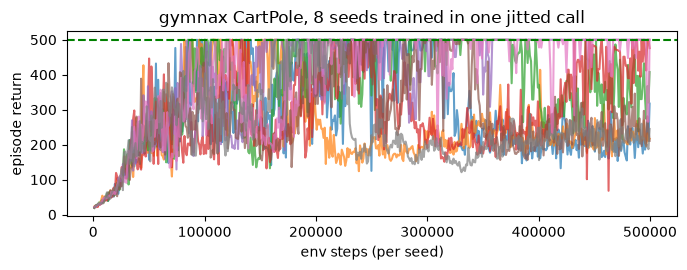

In [11]:
plt.figure(figsize=(7, 2.8))
steps_axis = (np.arange(G_UPDATES) + 1) * G["n_envs"] * G["n_steps"]
for s in range(N_SEEDS):
    plt.plot(steps_axis, curves[s], alpha=0.7)
plt.axhline(500, color="green", ls="--"); plt.xlabel("env steps (per seed)"); plt.ylabel("episode return")
plt.title(f"gymnax CartPole, {N_SEEDS} seeds trained in one jitted call"); plt.tight_layout(); plt.show()

## 6. Three JAX failure modes that raise no error

### 6a. Reusing a random key

`jax.random` is a pure function of the key. The same key gives the same "random"
number, every time. In a rollout loop, forgetting to `split` the key means every
step samples with identical noise.

In [12]:
logits = jnp.log(jnp.array([[0.25, 0.25, 0.25, 0.25]] * 16))     # 16 envs, uniform policy
key = jax.random.PRNGKey(0)
bad = np.array([np.asarray(jax.random.categorical(key, logits)) for _ in range(200)])   # key never split
good, k = [], key
for _ in range(200):
    k, sub = jax.random.split(k); good.append(np.asarray(jax.random.categorical(sub, logits)))
good = np.array(good)
print("same key every step : distinct action vectors over 200 steps =", len({tuple(r) for r in bad}))
print("split every step    : distinct action vectors over 200 steps =", len({tuple(r) for r in good}))

same key every step : distinct action vectors over 200 steps = 1
split every step    : distinct action vectors over 200 steps = 200


With the key never split, the "stochastic" policy picks the same 16 actions at every
step: exploration is gone, and the loss curves still look like training.

### 6b. Timing without `block_until_ready`

JAX dispatches work **asynchronously**: a call returns as soon as the work is
queued, not when it is done. A timer around an un-blocked call measures the queue.

In [13]:
A = jax.random.normal(jax.random.PRNGKey(0), (2000, 2000))
matmul = jax.jit(lambda a: (a @ a) @ a)
matmul(A).block_until_ready()
t = time.perf_counter(); out = matmul(A); t_queued = time.perf_counter() - t
out.block_until_ready()
t = time.perf_counter(); matmul(A).block_until_ready(); t_real = time.perf_counter() - t
print(f"without block_until_ready: {1e3 * t_queued:7.2f} ms  |  with: {1e3 * t_real:7.2f} ms")

without block_until_ready:    0.09 ms  |  with:   26.62 ms


### 6c. Silent recompilation

`jit` compiles once **per distinct static input** — a new array shape, or a Python
scalar used as a static argument. Code that passes a changing Python number into a
jitted function recompiles on every call and is slower than no `jit` at all. A
Python `print` inside the function runs only while tracing, so it counts the
compiles.

In [14]:
from functools import partial
traces = []
@partial(jax.jit, static_argnums=1)
def discount(rewards, gamma):
    traces.append(gamma)                        # runs at trace time only
    return jnp.sum(rewards * gamma ** jnp.arange(rewards.shape[0]))

r = jnp.ones(256)
t = time.perf_counter()
for g in np.linspace(0.9, 0.999, 50):           # a gamma sweep, passed as a static Python float
    discount(r, float(g)).block_until_ready()
t_static = time.perf_counter() - t
print(f"static gamma: {len(traces)} compiles for 50 calls, {t_static:.2f} s")

traces.clear()
discount_dyn = jax.jit(lambda rewards, gamma: (traces.append(1), jnp.sum(rewards * gamma ** jnp.arange(rewards.shape[0])))[1])
t = time.perf_counter()
for g in np.linspace(0.9, 0.999, 50):
    discount_dyn(r, jnp.float32(g)).block_until_ready()
print(f"traced gamma: {len(traces)} compile(s) for 50 calls, {time.perf_counter() - t:.2f} s")

static gamma: 50 compiles for 50 calls, 1.10 s
traced gamma: 1 compile(s) for 50 calls, 0.02 s


## 7. What the numbers say

Measured on one seed per LunarLander run, on an Apple M-series laptop CPU that was also running a 6-worker training job.

| run | env | steps | wall | steps/s | greedy mean, 100 episodes | at 200+ |
|---|---|---|---|---|---|---|
| from-scratch PPO, run A | LunarLander | 2.0M | 101 s | 19.8k | 23.8 | 0% |
| from-scratch PPO, run B | LunarLander | 2.0M | 92 s | 21.7k | 271.9 | 99% |
| SBX PPO | LunarLander | 1.0M | 599 s | 1,670 | 255.9 | 100% |
| SB3 PPO (torch) | LunarLander | 1.0M | 610 s | 1,639 | 255.7 | 99% |
| SBX DQN | LunarLander | 300k | 331 s | 907 | 255.8 | 90% |
| gymnax PPO, 8 seeds in one call | CartPole | 4.0M | 16.5 s | 242k | 217 to 500 per seed | — |

1. **The run that did not learn raised no error.** Run A plateaued near +90 with a greedy score of 23.8.
   Its health panel said why before the return did: approximate KL mostly below 1e-3 and clip fraction mostly 0, against 2e-3 to 7e-3 and 2% to 9% in run B. The policy barely moved.
   Eight times more gradient steps per sample and a constant learning rate (run B) took the same code to 271.9.
2. **JAX inside SB3 did not make it faster here.** SBX PPO and SB3 PPO ran at 1,670 and 1,639 steps per second with the same settings and scores.
   With a CPU simulator and 64-sample minibatches, the framework is not the bottleneck.
3. **Fusing the update did.** The from-scratch PPO takes the same number of gradient steps per sample as the SB3 settings (run B), and ran about 13 times faster per environment step.
   Its update phase, all 256 minibatch steps of each update in one `lax.scan`, took 15 s of the 92 s; the Box2D loop took 54 s.
   HYPOTHESIS (not profiled): SB3 and SBX spend most of their time dispatching one minibatch at a time from Python.
4. **The "100x" needs the environment in JAX.** With gymnax, eight seeds of CartPole trained at 242k steps per second in one call.
   That is not a like-for-like comparison: CartPole is far cheaper to simulate than Box2D, and the seeds spread widely: three ended above 400, one at 366, four between 217 and 249.
5. **The three silent failure modes, measured:** a reused key gave 1 distinct action vector in 200 steps (200 with `split`);
   timing without `block_until_ready` read 0.09 ms for a 26.6 ms computation; a static Python `gamma` compiled 50 times in 50 calls (1.10 s against 0.02 s).